<a href="https://colab.research.google.com/github/anderson-perez/IAC/blob/main/Introdu%C3%A7%C3%A3o.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Segunda Parte da Disciplina

# Informações:

- Prof. Anderson Luiz Fernandes Perez
- Contato: anderson.perez@ufsc.br | anderson.lfp@gmail.com
- Os materiais da disciplina estarão disponíveis no github (https://github.com/anderson-perez/IAC.git)

# Métodos de Avaliação de Algoritmos de Aprendizado de Máquina

A avaliação é uma etapa fundamental em **Aprendizado de Máquina**. Um modelo não deve apenas aprender os exemplos usados no treinamento: deve ser capaz de **generalizar** para novos dados.

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification, make_regression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, precision_score,
    recall_score, f1_score, mean_absolute_error, mean_squared_error,
    r2_score, roc_curve, roc_auc_score, precision_recall_curve)

np.random.seed(42)

## Objetivo da Avaliação de Modelos de AM

Durante o treinamento, um algoritmo ajusta seus parâmetros aos exemplos disponíveis. Entretanto, um bom resultado nos dados de treinamento não garante bom desempenho com novos exemplos.

O objetivo da avaliação é estimar a **capacidade de generalização** do modelo.

$$
\text{Dados de treinamento}\rightarrow\text{Modelo}\rightarrow\text{Novos dados}\rightarrow\text{Avaliação}
$$

Por isso, a avaliação final não deve ser realizada apenas com os mesmos exemplos utilizados para ajustar o modelo.

## Treinamento, Validação e Teste

Os dados podem ser separados em três conjuntos:

- **Treinamento:** utilizado para ajustar os parâmetros do modelo.
- **Validação:** utilizado durante o desenvolvimento para comparar configurações e hiperparâmetros.
- **Teste:** utilizado para a avaliação final, após as decisões de desenvolvimento.

Uma divisão ilustrativa seria $(70\%)$ para treinamento, $(15\%)$ para validação e $(15\%)$ para teste. Esses valores não constituem uma regra.

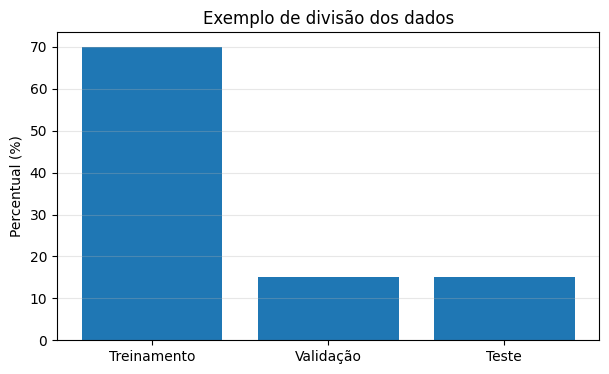

In [2]:
plt.figure(figsize=(7,4))
plt.bar(["Treinamento","Validação","Teste"], [70,15,15])
plt.ylabel("Percentual (%)")
plt.title("Exemplo de divisão dos dados")
plt.grid(axis="y", alpha=0.3)
plt.show()

## Holdout

Uma estratégia simples consiste em separar os dados em treinamento e teste:

$$
D=D_{treino}\cup D_{teste}
$$

O treinamento ajusta o modelo e o teste estima seu desempenho em exemplos não utilizados nesse ajuste.

In [3]:
X, y = make_classification(n_samples=500, n_features=5, n_informative=3,
                           n_redundant=0, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)

print("Total:", len(X))
print("Treinamento:", len(X_train))
print("Teste:", len(X_test))

Total: 500
Treinamento: 400
Teste: 100


O parâmetro `stratify=y` procura manter aproximadamente a proporção das classes nos dois conjuntos.

## Generalização, Underfitting e Overfitting

**Underfitting:** o modelo é simples demais para representar adequadamente os padrões. O desempenho tende a ser ruim tanto no treinamento quanto em novos dados.

**Ajuste adequado:** o modelo aprende padrões relevantes e mantém desempenho satisfatório em dados não vistos.

**Overfitting:** o modelo se ajusta excessivamente aos exemplos de treinamento, inclusive a ruídos e particularidades, mas apresenta pior desempenho em novos dados.

O objetivo não é maximizar simplesmente o desempenho no treinamento, mas obter **boa generalização**.

# Avaliação de Classificação

Em classificação o modelo prevê uma categoria.

In [4]:
modelo = LogisticRegression(max_iter=1000)
modelo.fit(X_train, y_train)
y_pred = modelo.predict(X_test)
probabilidades = modelo.predict_proba(X_test)[:,1]

## Matriz de Confusão

Para classificação binária:

| | Previsto negativo | Previsto positivo |
|---|---:|---:|
| **Real negativo** | TN | FP |
| **Real positivo** | FN | TP |

- **TP:** verdadeiro positivo;
- **TN:** verdadeiro negativo;
- **FP:** falso positivo;
- **FN:** falso negativo.

[[42  8]
 [ 6 44]]


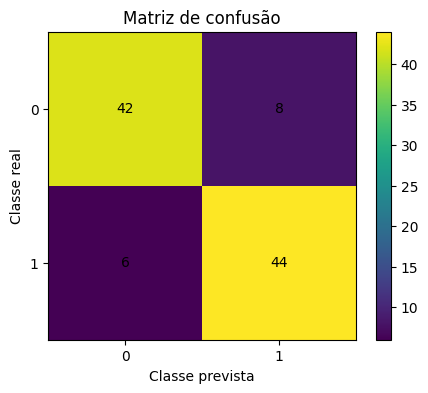

In [22]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

plt.figure(figsize=(5,4))
plt.imshow(cm)
plt.xlabel("Classe prevista")
plt.ylabel("Classe real")
plt.title("Matriz de confusão")
plt.xticks([0,1]); plt.yticks([0,1])
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i,j], ha="center", va="center")
plt.colorbar()
plt.show()



## Acurácia

$$
Accuracy=\frac{TP+TN}{TP+TN+FP+FN}
$$

A acurácia representa a proporção total de previsões corretas. É intuitiva, mas pode ser enganosa em conjuntos desbalanceados.

Por exemplo, se 990 de 1.000 exemplos pertencem à classe 0, um modelo que sempre responda 0 terá 99% de acurácia, mesmo sem identificar nenhum exemplo da classe minoritária.

In [6]:
acc = accuracy_score(y_test, y_pred)
print(f"Acurácia: {acc:.4f}")

Acurácia: 0.8600


## Precisão

A **precisão (precision)** responde: entre os exemplos classificados como positivos, quantos realmente eram positivos?

$$
Precision=\frac{TP}{TP+FP}
$$

É especialmente relevante quando falsos positivos têm custo elevado.

In [7]:
precision = precision_score(y_test, y_pred)
print(f"Precision: {precision:.4f}")

Precision: 0.8462


## Revocação

A **revocação (recall)** responde: entre todos os exemplos realmente positivos, quantos foram identificados?

$$
Recall=\frac{TP}{TP+FN}
$$

É especialmente relevante quando falsos negativos têm custo elevado.

In [8]:
recall = recall_score(y_test, y_pred)
print(f"Recall: {recall:.4f}")

Recall: 0.8800


## F1-score

O F1-score representa a média harmônica entre precision e recall:

$$
F_1=2\frac{Precision\cdot Recall}{Precision+Recall}
$$

É útil quando deseja-se considerar conjuntamente essas duas métricas.

In [9]:
f1 = f1_score(y_test, y_pred)
pd.DataFrame({"Métrica":["Acurácia","Precision","Recall","F1-score"],
              "Valor":[acc,precision,recall,f1]})

,Métrica,Valor
0,Acurácia,0.860000
1,Precision,0.846154
2,Recall,0.880000
3,F1-score,0.862745


## Limiar de Decisão

Muitos classificadores produzem uma pontuação ou probabilidade. Uma classe pode ser escolhida comparando esse valor com um **limiar**:

$$
P(y=1|x)\geq 0.5\Rightarrow\hat y=1
$$

Alterar o limiar modifica a relação entre falsos positivos e falsos negativos e, consequentemente, entre precision e recall.

In [10]:
for limiar in [0.3, 0.5, 0.7]:
    pred = (probabilidades >= limiar)
    print(f"Limiar {limiar:.1f} | Precision={precision_score(y_test,pred):.3f} | Recall={recall_score(y_test,pred):.3f}")

Limiar 0.3 | Precision=0.821 | Recall=0.920
Limiar 0.5 | Precision=0.846 | Recall=0.880
Limiar 0.7 | Precision=0.911 | Recall=0.820


## Curva ROC e AUC

A curva ROC relaciona a taxa de verdadeiros positivos (TPR) e a taxa de falsos positivos (FPR) para diferentes limiares.

$$
TPR=\frac{TP}{TP+FN}
\qquad
FPR=\frac{FP}{FP+TN}
$$

A **AUC** resume a área sob a curva ROC. A interpretação deve considerar o contexto e a distribuição das classes.

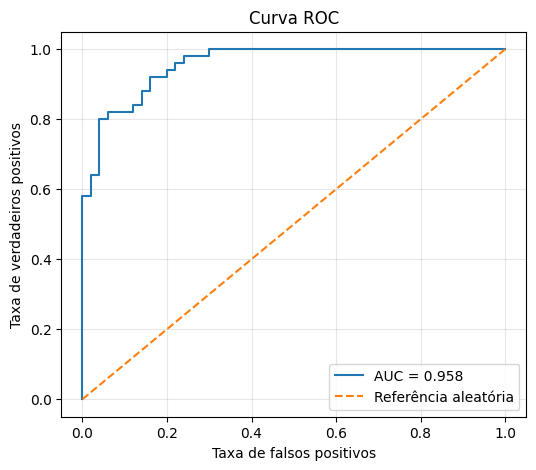

In [11]:
fpr, tpr, _ = roc_curve(y_test, probabilidades)
auc = roc_auc_score(y_test, probabilidades)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.plot([0,1],[0,1],"--",label="Referência aleatória")
plt.xlabel("Taxa de falsos positivos")
plt.ylabel("Taxa de verdadeiros positivos")
plt.title("Curva ROC")
plt.legend(); plt.grid(True,alpha=0.3); plt.show()

## Curva Precision-Recall

A curva Precision-Recall mostra o compromisso entre essas duas métricas para diferentes limiares. Ela pode ser especialmente informativa quando existe forte desbalanceamento e a classe positiva é de especial interesse.

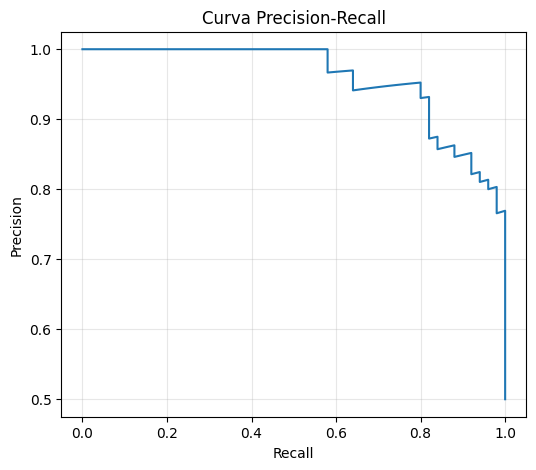

In [12]:
precisions, recalls, _ = precision_recall_curve(y_test, probabilidades)

plt.figure(figsize=(6,5))
plt.plot(recalls, precisions)
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title("Curva Precision-Recall")
plt.grid(True,alpha=0.3); plt.show()

# Avaliação de Regressão

Em regressão, a saída é numérica. Desta forma, o objetivo é analisar a diferença entre o valor real $(y_i)$ e a previsão $(\hat y_i)$.

In [13]:
X_reg, y_reg = make_regression(n_samples=300, n_features=3, noise=20, random_state=42)
Xtr, Xte, ytr, yte = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

modelo_reg = LinearRegression()
modelo_reg.fit(Xtr, ytr)
yp = modelo_reg.predict(Xte)

## Erro Absoluto Médio - MAE (*Mean Absolute Error*)

$$
MAE=\frac{1}{n}\sum_{i=1}^{n}|y_i-\hat y_i|
$$

O MAE possui a mesma unidade da variável prevista e apresenta interpretação direta.

In [14]:
mae = mean_absolute_error(yte, yp)
print(f"MAE: {mae:.4f}")

MAE: 14.0320


## Erro Quadrático Médio - MSE (*Mean Squared Error*)

$$
MSE=\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat y_i)^2
$$

Como os erros são elevados ao quadrado, erros grandes recebem maior penalização.

In [15]:
mse = mean_squared_error(yte, yp)
print(f"MSE: {mse:.4f}")

MSE: 303.6699


## Raiz do Erro Quadrático Médio - RMSE (*Root Mean Squared Error*)

$$
RMSE=\sqrt{MSE}
$$

O RMSE também penaliza erros grandes, mas retorna à mesma unidade da variável prevista.

In [16]:
rmse = np.sqrt(mse)
print(f"RMSE: {rmse:.4f}")

RMSE: 17.4261


## Coeficiente de Determinação — $(R^2)$

$$
R^2=1-\frac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y)^2}
$$

- $(R^2=1)$: previsões perfeitas;
- $(R^2=0)$: desempenho equivalente à referência que prevê a média;
- $(R^2<0)$: desempenho pior que essa referência.

O $(R^2)$ não deve ser interpretado isoladamente.

In [17]:
r2 = r2_score(yte, yp)
pd.DataFrame({"Métrica":["MAE","MSE","RMSE","R²"],"Valor":[mae,mse,rmse,r2]})

,Métrica,Valor
0,MAE,14.031962
1,MSE,303.669927
2,RMSE,17.426128
3,R²,0.981685


## Valores reais × Previstos

Uma avaliação gráfica complementa as métricas numéricas. Em uma previsão ideal, os pontos ficariam sobre a reta $(\hat y=y)$.

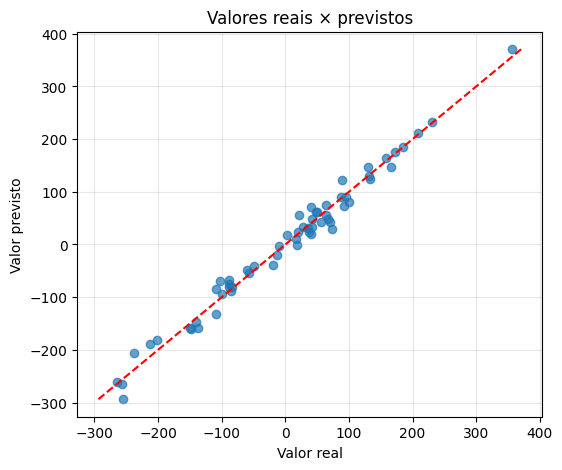

In [24]:
plt.figure(figsize=(6,5))
plt.scatter(yte, yp, alpha=0.7)
a=min(yte.min(),yp.min()); b=max(yte.max(),yp.max())
plt.plot([a,b],[a,b],"--", color='red')
plt.xlabel("Valor real"); plt.ylabel("Valor previsto")
plt.title("Valores reais × previstos")
plt.grid(True,alpha=0.3); plt.show()

## Análise dos Resíduos

O resíduo é:

$$
e_i=y_i-\hat y_i
$$

A análise gráfica dos resíduos pode revelar padrões que uma única métrica numérica não evidencia. Em muitos problemas, espera-se que não exista um padrão sistemático evidente nos resíduos.

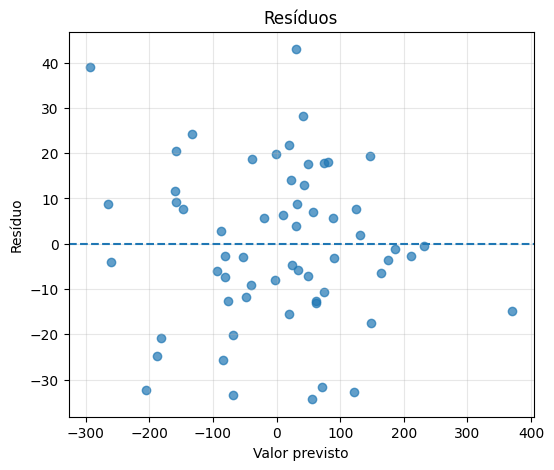

In [19]:
residuos = yte - yp
plt.figure(figsize=(6,5))
plt.scatter(yp, residuos, alpha=0.7)
plt.axhline(0, linestyle="--")
plt.xlabel("Valor previsto"); plt.ylabel("Resíduo")
plt.title("Resíduos")
plt.grid(True,alpha=0.3); plt.show()

## Qual a Melhor Métrica?

Não existe uma métrica universalmente melhor. A escolha depende do objetivo e do custo dos erros.

### Classificação
- **Acurácia:** útil quando as classes são razoavelmente equilibradas e os erros têm importância semelhante.
- **Precision:** importante quando falsos positivos são particularmente indesejáveis.
- **Recall:** importante quando falsos negativos são particularmente indesejáveis.
- **F1-score:** combina precision e recall.
- **ROC-AUC:** analisa discriminação ao longo de diferentes limiares.
- **Precision-Recall:** frequentemente informativa em problemas desbalanceados.

### Regressão
- **MAE:** interpretação direta e menor influência de erros extremos que métricas quadráticas.
- **MSE:** penaliza fortemente erros grandes.
- **RMSE:** penaliza erros grandes e mantém a unidade original.
- **$(R^2)$:** compara o modelo com uma referência baseada na média.

## Vazamento de Dados

Uma avaliação correta deve impedir que informações reservadas para validação ou teste influenciem o treinamento. O uso indevido dessas informações é chamado de **data leakage** (vazamento de dados).

Operações como padronização, seleção de características, redução de dimensionalidade e escolha de hiperparâmetros devem ser realizadas sem utilizar indevidamente informações do conjunto de teste.

Também não é apropriado consultar repetidamente o conjunto de teste para escolher o modelo, pois ele deixaria de representar uma avaliação final independente.

## Fluxo para um Modelo de AM

$$
\boxed{\text{Dados}}
\rightarrow
\boxed{\text{Treinamento}}
\rightarrow
\boxed{\text{Validação}}
\rightarrow
\boxed{\text{Escolha}}
\rightarrow
\boxed{\text{Teste final}}
$$

A validação cruzada pode substituir ou complementar um conjunto de validação separado. O princípio fundamental é manter a **avaliação final independente das decisões tomadas durante o desenvolvimento**.